<a href="https://colab.research.google.com/github/Perez-Alvaro/uber-lyft-dataset/blob/main/Contenido%20Entrega%203%20mejoras/2_Presentacion_Colab/Presentacion_Entrega3_Grupo11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

# ¿Cuánto cuesta un viaje y cuándo hay recargo?
## Entrega 3 · Modelado y análisis de resultados

**Uber y Lyft en Boston** · Grupo 11 · Ciencia de Datos 5K1 · UTN FRC · 30/10/2026

Álvaro Pérez · Juan Ignacio Cremona · Ignacio Gil · Federico Gon · Sofía Medina · Facundo Dagnino Dailly

---

**Recorrido:** 1 El problema · 2 Cómo trabajamos · 3 Qué modelos usamos y por qué · 4 Qué probamos y cómo elegimos · 5 Precio · 6 Recargo y accuracy · 7 Balanceo · 8 Modelo final · 9 Qué aprendimos · 10 Rutas · 11 Conclusiones

> *Entorno de ejecución → Ejecutar todo* (menos de 30 segundos). El código está oculto: se ve solo el resultado de cada celda.

In [1]:
# @title Preparación (carga los resultados) { display-mode: "form" }
import json, re, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

CARPETA = "Contenido Entrega 3 mejoras"

def buscar_raiz():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "6_Resultados" / "metricas.json").exists():
            return base
        if (base / CARPETA / "6_Resultados" / "metricas.json").exists():
            return base / CARPETA
    return None

RAIZ = buscar_raiz()
if RAIZ is None:  # en Colab: se descarga el repositorio una sola vez
    subprocess.run(["git", "clone", "-q", "--depth", "1",
                    "https://github.com/Perez-Alvaro/uber-lyft-dataset.git"], check=True)
    RAIZ = Path("uber-lyft-dataset") / CARPETA

GRAF, RES, DATOS = RAIZ / "5_Graficos", RAIZ / "6_Resultados", RAIZ / "4_Datasets"
M = json.loads(re.sub(r"\bNaN\b", "null", (RES / "metricas.json").read_text(encoding="utf-8")))

def figura(nombre, ancho=1000):
    display(Image(filename=str(GRAF / nombre), width=ancho))

def tabla(df):
    display(df.style.hide(axis="index").set_properties(**{"text-align": "left", "font-size": "13px"})
              .set_table_styles([{"selector": "th", "props": [("text-align", "left"), ("background", "#F2F2F2"), ("font-size", "13px")]}]))

num = lambda x, d=3: f"{x:.{d}f}".replace(".", ",")
pct = lambda x, d=1: f"{100 * x:.{d}f}".replace(".", ",") + "%"
usd = lambda x: "USD " + num(x, 2)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
print("Listo: resultados cargados")

Listo: resultados cargados


## 1 · El problema

**Pregunta del proyecto:** ¿qué determina el precio de un viaje y qué tan bien lo podemos predecir?

| | Objetivo 1 | Objetivo 2 |
|---|---|---|
| **Pregunta** | ¿Cuánto cuesta el viaje? | ¿Este viaje tiene recargo? |
| **Variable** | `price` (USD) | `has_surge` (sí / no) |
| **Tipo** | Regresión | Clasificación |
| **Datos** | Uber + Lyft · 636.568 cotizaciones | Lyft · 255.953 cotizaciones |

Partimos del **dataset codificado** de la Entrega 2.

## 2 · Cómo trabajamos

1. **Separar por fecha.** Entrenamos con el pasado (25/11 al 14/12) y probamos con **4 días nuevos** (15 al 18/12). Si mezcláramos al azar, el modelo vería cotizaciones "gemelas" del mismo minuto y parecería mejor de lo que es.
2. **Probar varios modelos y configuraciones.** Cada modelo se probó con distintos parámetros.
3. **Elegir con validación**, usando solo fechas de entrenamiento: entrenamos con los primeros días y validamos con los siguientes. **La prueba final no se usa para elegir nada.**
4. **Evaluar** el modelo elegido en los 4 días de prueba e **interpretar** qué aprendió.

## 3 · Qué modelos usamos y por qué

Elegimos modelos de **menor a mayor complejidad**, para ver si la complejidad extra vale la pena:

| Modelo | Para qué | Por qué lo elegimos |
|---|---|---|
| **Regresión lineal (Ridge) / logística** | Precio / recargo | Simple e interpretable: es la referencia. La logística es el modelo base de clasificación de la cátedra. |
| **Árbol de decisión** | Ambos | Da reglas fáciles de explicar ("si sale de tal zona y la distancia es menor a…") y capta escalones. |
| **Random forest** | Ambos | Muchos árboles promediados: más estable que un árbol solo. |
| **Gradient boosting** | Recargo | Árboles en serie, cada uno corrige al anterior (la idea de AdaBoost). Suele ser el más preciso. |
| **K-Means** | Rutas | Agrupa rutas parecidas sin variable objetivo (no supervisado). |

## 4 · Qué probamos y cómo elegimos

Cada modelo se probó con **varias configuraciones** (por ejemplo, árboles más o menos profundos). Para cada uno mostramos tres pruebas: una **más simple**, una **más compleja** y la **elegida**, que es la que mejor rindió en validación.

In [2]:
# @title Tres pruebas por modelo de recargo (puntaje en validación: más alto es mejor) { display-mode: "form" }
filas = []
for modelo, pruebas in M["A_pruebas"].items():
    por_rol = {p["rol"].split(" (")[0]: p for p in pruebas}
    fila = {"Modelo": modelo}
    for rol in ["Más simple", "Elegida", "Más compleja"]:
        p = por_rol.get(rol)
        fila[rol] = f'{num(p["validacion"])}' if p else "= elegida"
    fila["Configuración elegida"] = por_rol["Elegida"]["params"]
    filas.append(fila)
tabla(pd.DataFrame(filas))

Modelo,Más simple,Elegida,Más compleja,Configuración elegida
Regresión logística,= elegida,"0,120","0,112",C=0.0001
Árbol de decisión,"0,114","0,125","0,103",criterion=gini · max_depth=12 · min_samples_leaf=500
Random forest,"0,125","0,126",= elegida,max_depth=16 · min_samples_leaf=10
Gradient boosting,= elegida,"0,136","0,133",learning_rate=0.05 · max_leaf_nodes=15


Puntaje: **PR-AUC en validación** (el azar da 0,08). La configuración más compleja rinde muy bien en entrenamiento pero no en días nuevos: **memoriza**.

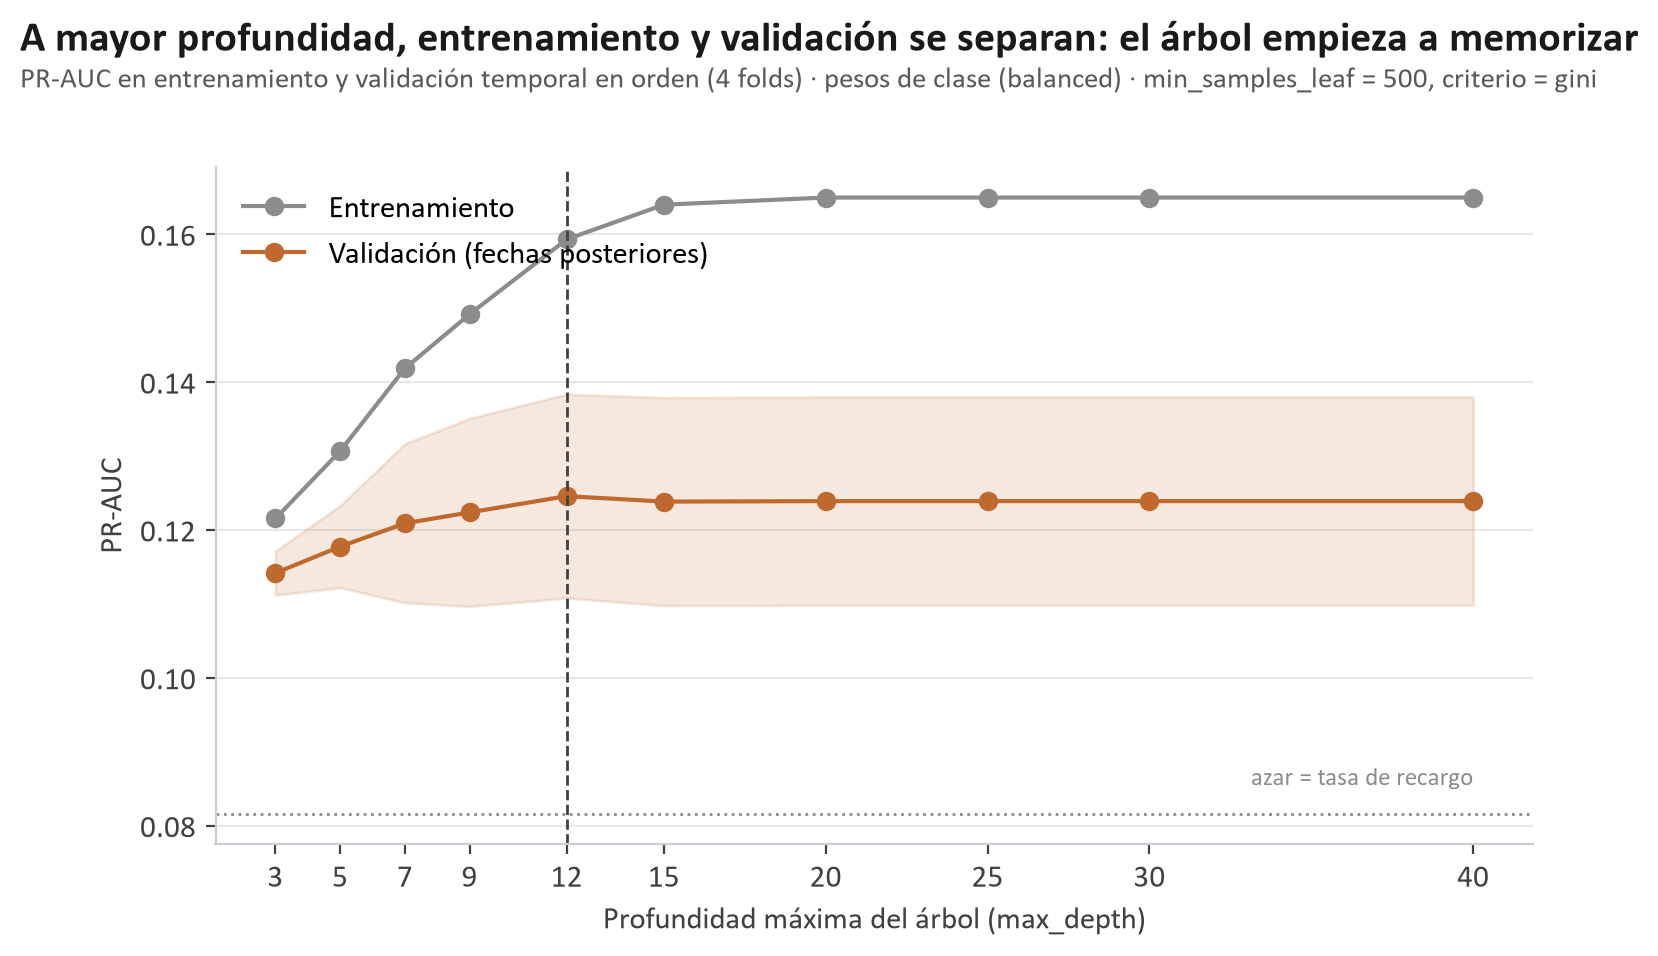

In [3]:
# @title Figura 3 · Ejemplo: probar distintas profundidades del árbol { display-mode: "form" }
figura("fig03_recargo_validacion_profundidad.png", 800)

Más profundidad mejora en entrenamiento pero **no en días nuevos**: el árbol empieza a memorizar. Elegimos el punto donde la validación deja de mejorar.

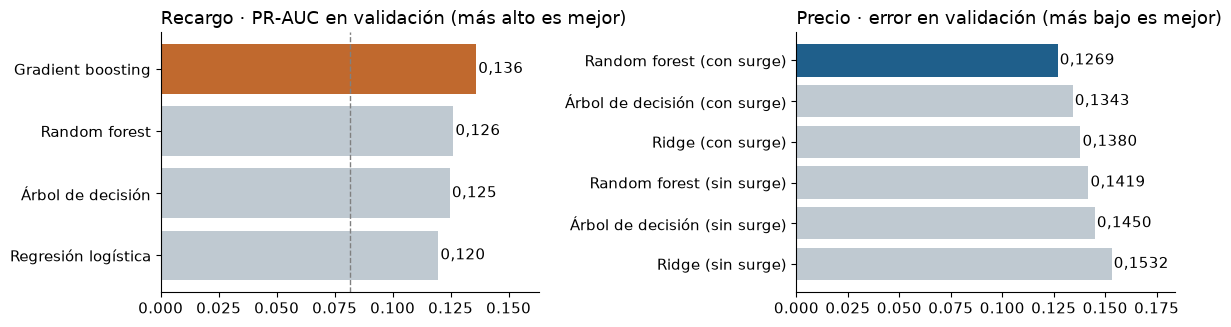

In [4]:
# @title Y entre modelos: ¿cuál rindió mejor en validación? { display-mode: "form" }
sel = sorted(M["A_seleccion"], key=lambda s: s["pr_auc_val"])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
colores = ["#C0692E" if s["modelo"] == M["A_elegido"] else "#BFC9D1" for s in sel]
axes[0].barh([s["modelo"] for s in sel], [s["pr_auc_val"] for s in sel], color=colores)
for i, s in enumerate(sel):
    axes[0].text(s["pr_auc_val"] + 0.001, i, num(s["pr_auc_val"]), va="center")
axes[0].axvline(M["A_datos"]["tasa_train"], color="gray", ls="--", lw=1)
axes[0].set_xlim(0, max(s["pr_auc_val"] for s in sel) * 1.2)
axes[0].set_title("Recargo · PR-AUC en validación (más alto es mejor)", loc="left")
precio = sorted([(f'{m} ({v})', t["rmse_log_cv"]) for m, vs in M["B_tuning"].items() for v, t in vs.items()], key=lambda x: -x[1])
elegido_b = f'{M["B_mejor"]["modelo"]} ({M["B_mejor"]["variante"]})'
axes[1].barh([p[0] for p in precio], [p[1] for p in precio], color=["#1F5F8B" if p[0] == elegido_b else "#BFC9D1" for p in precio])
for i, p in enumerate(precio):
    axes[1].text(p[1] + 0.001, i, num(p[1], 4), va="center")
axes[1].set_xlim(0, max(p[1] for p in precio) * 1.2)
axes[1].set_title("Precio · error en validación (más bajo es mejor)", loc="left")
plt.tight_layout(); plt.show()

- **Recargo:** gana **gradient boosting**, aunque los cuatro quedan cerca → el límite no es el algoritmo sino la información disponible.
- **Precio:** gana **random forest con surge**. Los árboles superan al modelo lineal porque la tarifa crece por escalones.

## 5 · Objetivo 1 · ¿Cuánto cuesta el viaje?

In [5]:
# @title Resultados en los 4 días de prueba { display-mode: "form" }
filas = [[r["modelo"].replace("Línea base: mediana por producto", "Línea base (solo el producto)"), r["variante"],
          usd(r["mae"]), pct(r["dentro_10pct"], 0), num(r["r2"])] for r in M["B_regresion"]]
tabla(pd.DataFrame(filas, columns=["Modelo", "Variante", "Error medio", "Viajes con error ≤ 10%", "R²"]))

Modelo,Variante,Error medio,Viajes con error ≤ 10%,R²
Línea base (solo el producto),-,"USD 3,04",34%,"0,758"
Ridge,sin surge,"USD 1,62",62%,"0,910"
Ridge,con surge,"USD 1,39",65%,"0,951"
Árbol de decisión,sin surge,"USD 1,35",71%,"0,927"
Árbol de decisión,con surge,"USD 1,09",74%,"0,966"
Random forest,sin surge,"USD 1,32",72%,"0,928"
Random forest,con surge,"USD 1,08",75%,"0,967"


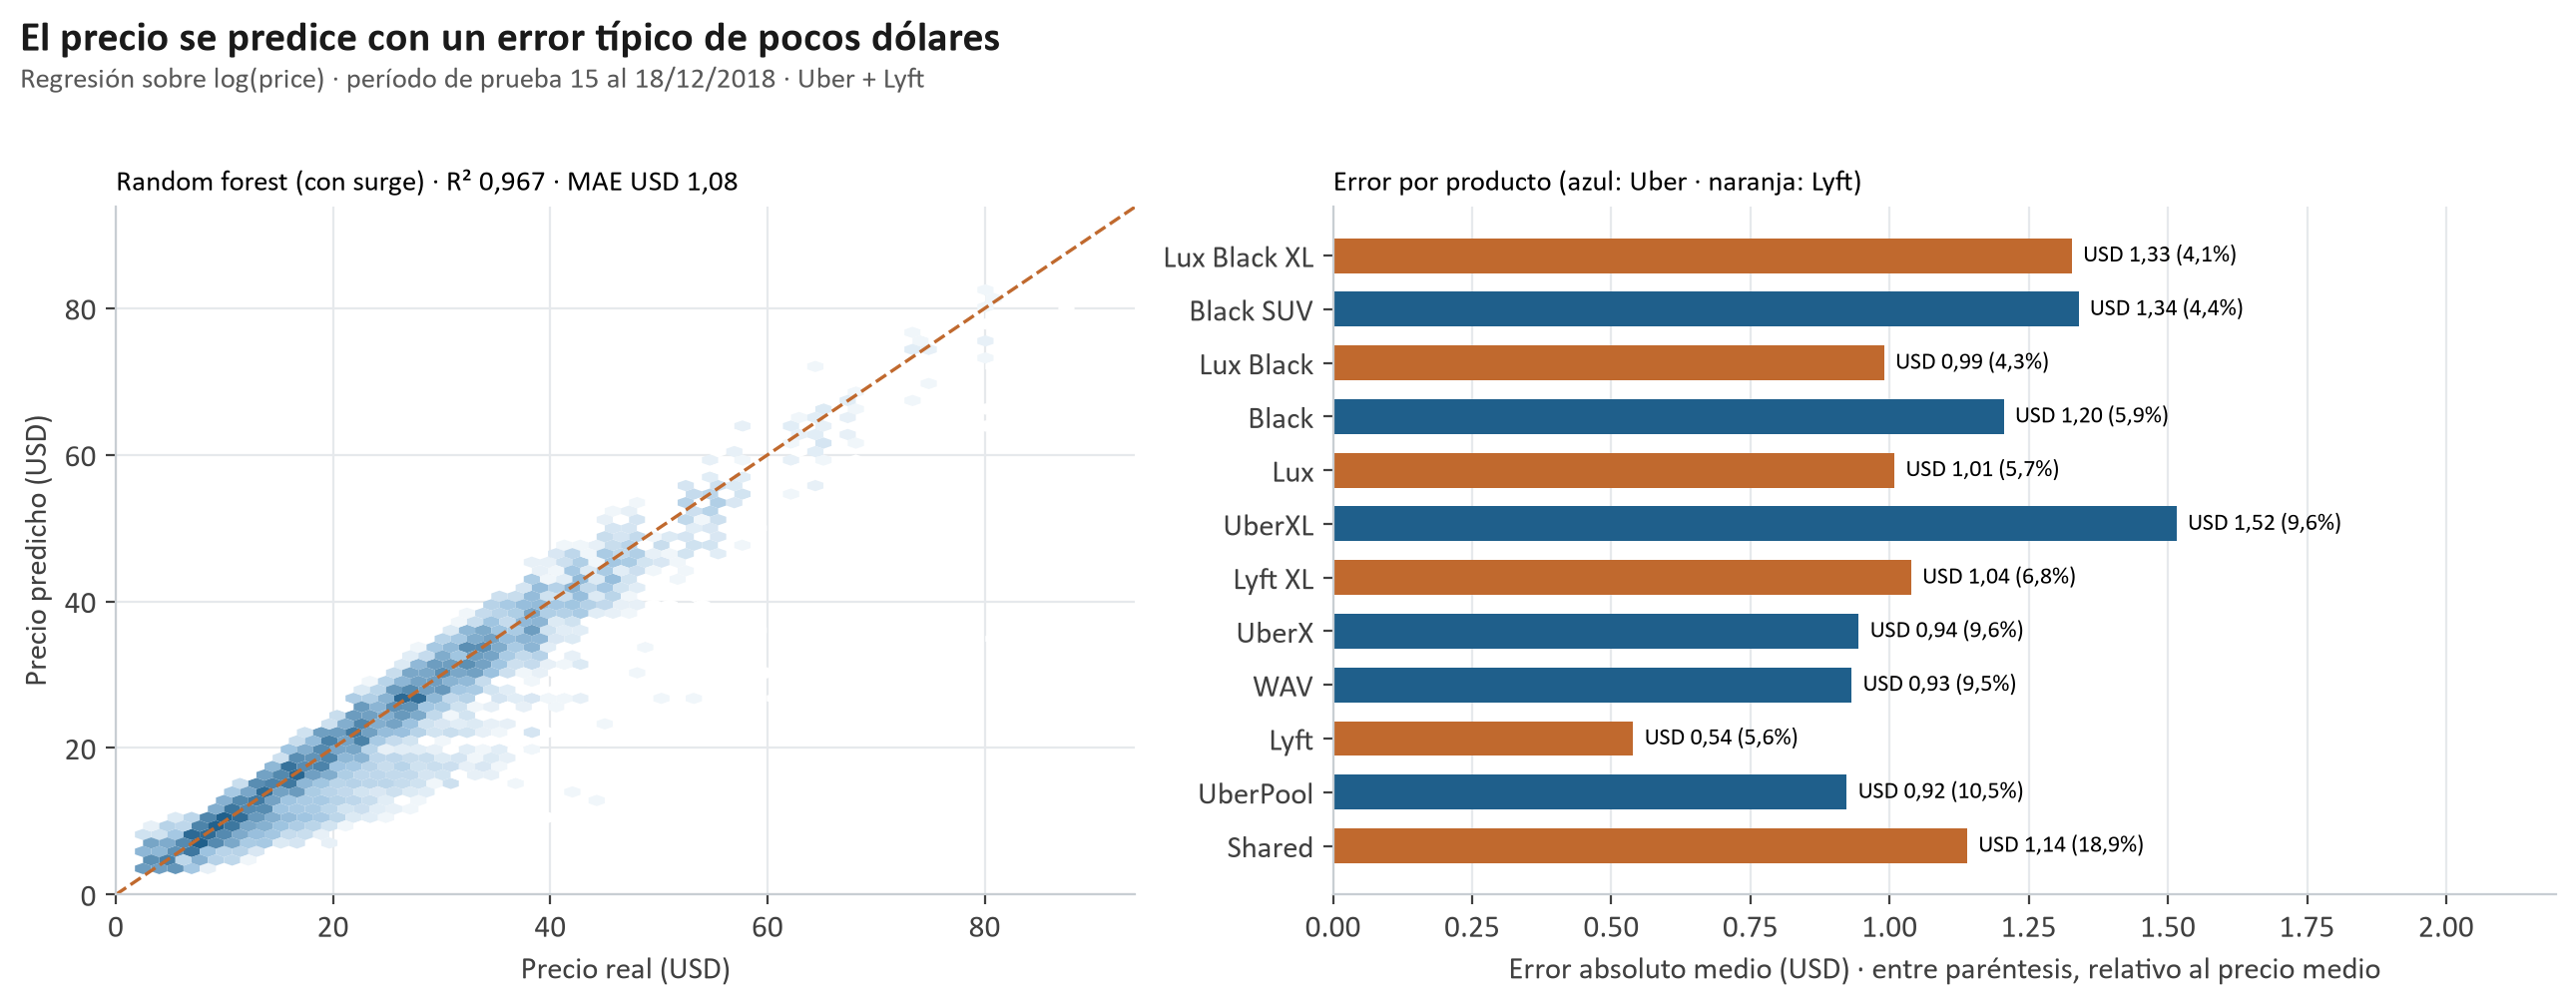

In [6]:
# @title Figura 1 · Precio real vs predicho { display-mode: "form" }
figura("fig01_precio_real_vs_predicho.png")

- El modelo elegido se equivoca en promedio **USD 1,08** y acierta el precio (con error ≤ 10%) en el **75%** de los viajes.
- Supera a la regresión lineal (USD 1,39 de error): la tarifa sube **por escalones**.
- Sin `surge_multiplier` el precio ya es predecible (R² = 0,928); con él, el error baja un 18%.

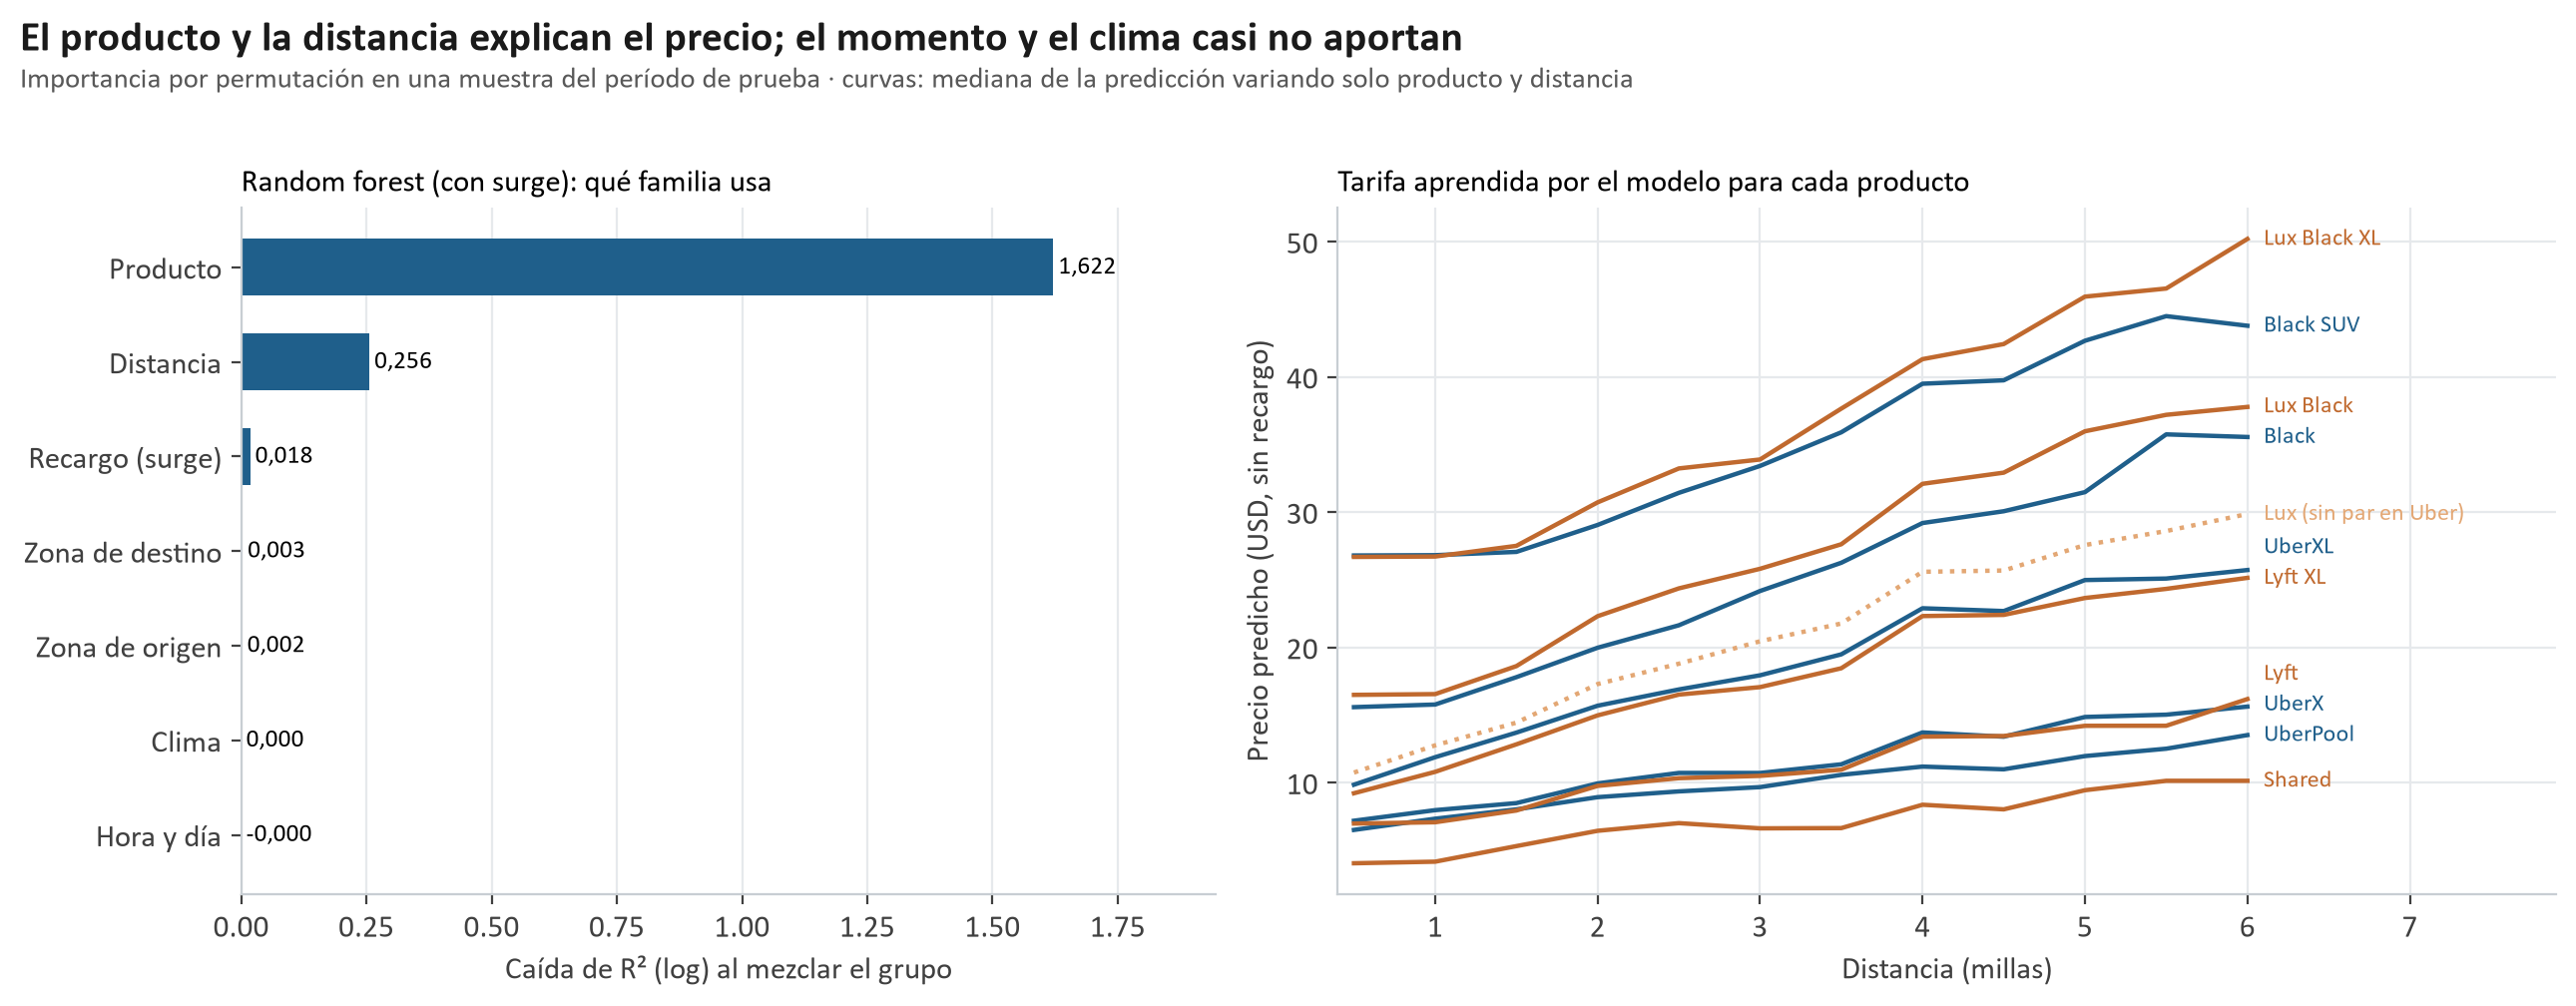

In [7]:
# @title Figura 2 · Qué usa el modelo y tarifa de cada producto { display-mode: "form" }
figura("fig02_precio_importancia_y_tarifas.png")

- **El producto y la distancia explican el precio** (H1). La hora y el clima no aportan.
- **Uber vs Lyft (H2):** Lyft es más barato en los económicos (Shared −29%) y más caro en los Black (+8%).

## 6 · Objetivo 2 · ¿Tiene recargo? El problema de la accuracy

Solo **8,2%** de las cotizaciones tiene recargo (1 de cada 12).

La **accuracy** es el % de predicciones correctas. Un "modelo" que dice **siempre "sin recargo"** tiene **91,7% de accuracy**… y no detecta ningún recargo.

Por eso miramos la accuracy **junto con**:
- **Accuracy balanceada:** promedio del acierto en cada clase (50% = azar).
- **Recall:** qué % de los recargos detecta.
- **Precisión:** de las alertas, cuántas son recargos reales.

### Demostración en vivo: el mismo árbol, sin balancear y balanceado

Árbol,Accuracy,Accuracy balanceada,Recall (recargos detectados),Precisión
Sin balancear,"91,7%","50,0%","0,0%","0,0%"
Con pesos de clase,"50,7%","62,8%","77,3%","11,9%"


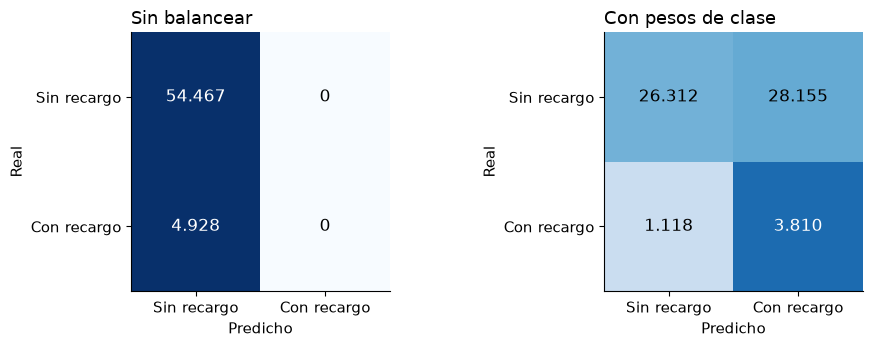

In [8]:
# @title Entrenar y comparar (≈10 segundos) { display-mode: "form" }
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, recall_score, precision_score, confusion_matrix

surge = pd.read_csv(DATOS / "datasets modelado" / "dataset_modelado_surge.zip")
predictoras = [c for c in surge.columns if c not in ("id", "datetime_local", "fecha", "particion", "has_surge", "ruta")]
tr, te = surge[surge["particion"] == "train"], surge[surge["particion"] == "test"]
resultados, matrices = [], []
for etiqueta, tecnica, pesos in [("Sin balancear", "sin", None), ("Con pesos de clase", "pesos", "balanced")]:
    params = M["A_tuning"]["Árbol de decisión"][tecnica]["params"]
    arbol = DecisionTreeClassifier(**params, class_weight=pesos, random_state=42).fit(tr[predictoras], tr["has_surge"])
    pred = arbol.predict(te[predictoras])
    resultados.append([etiqueta, pct(accuracy_score(te["has_surge"], pred)), pct(balanced_accuracy_score(te["has_surge"], pred)),
                       pct(recall_score(te["has_surge"], pred)), pct(precision_score(te["has_surge"], pred, zero_division=0))])
    matrices.append((etiqueta, confusion_matrix(te["has_surge"], pred)))
tabla(pd.DataFrame(resultados, columns=["Árbol", "Accuracy", "Accuracy balanceada", "Recall (recargos detectados)", "Precisión"]))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, (etiqueta, cm) in zip(axes, matrices):
    ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}".replace(",", "."), ha="center", va="center", fontsize=12,
                    color="white" if cm[i, j] / cm[i].sum() > 0.6 else "black")
    ax.set_xticks([0, 1], ["Sin recargo", "Con recargo"]); ax.set_yticks([0, 1], ["Sin recargo", "Con recargo"])
    ax.set_xlabel("Predicho"); ax.set_ylabel("Real"); ax.set_title(etiqueta, loc="left")
plt.tight_layout(); plt.show()

**Conclusión:** sin balancear, la accuracy es altísima pero el modelo casi nunca avisa de un recargo. Balanceando, la accuracy baja pero **la accuracy balanceada y el recall suben**: el modelo empieza a detectar recargos.

## 7 · Balanceo de clases: cuatro técnicas

El balanceo se aplica **solo al entrenamiento**; la prueba siempre mantiene la proporción real.

| Técnica | Qué hace | Filas para entrenar | % con recargo |
|---|---|---|---|
| Sin balanceo | Datos tal cual | 196.558 | 8,2% |
| Submuestreo | Descarta cotizaciones sin recargo | 32.094 | 50% |
| SMOTE | Inventa recargos "sintéticos" | 361.022 | 50% |
| **Pesos de clase** | No cambia los datos: equivocarse en un recargo "cuesta" 6,1 veces más | 196.558 | 8,2% |

Los datasets balanceados están en `4_Datasets/datasets balanceados/`.

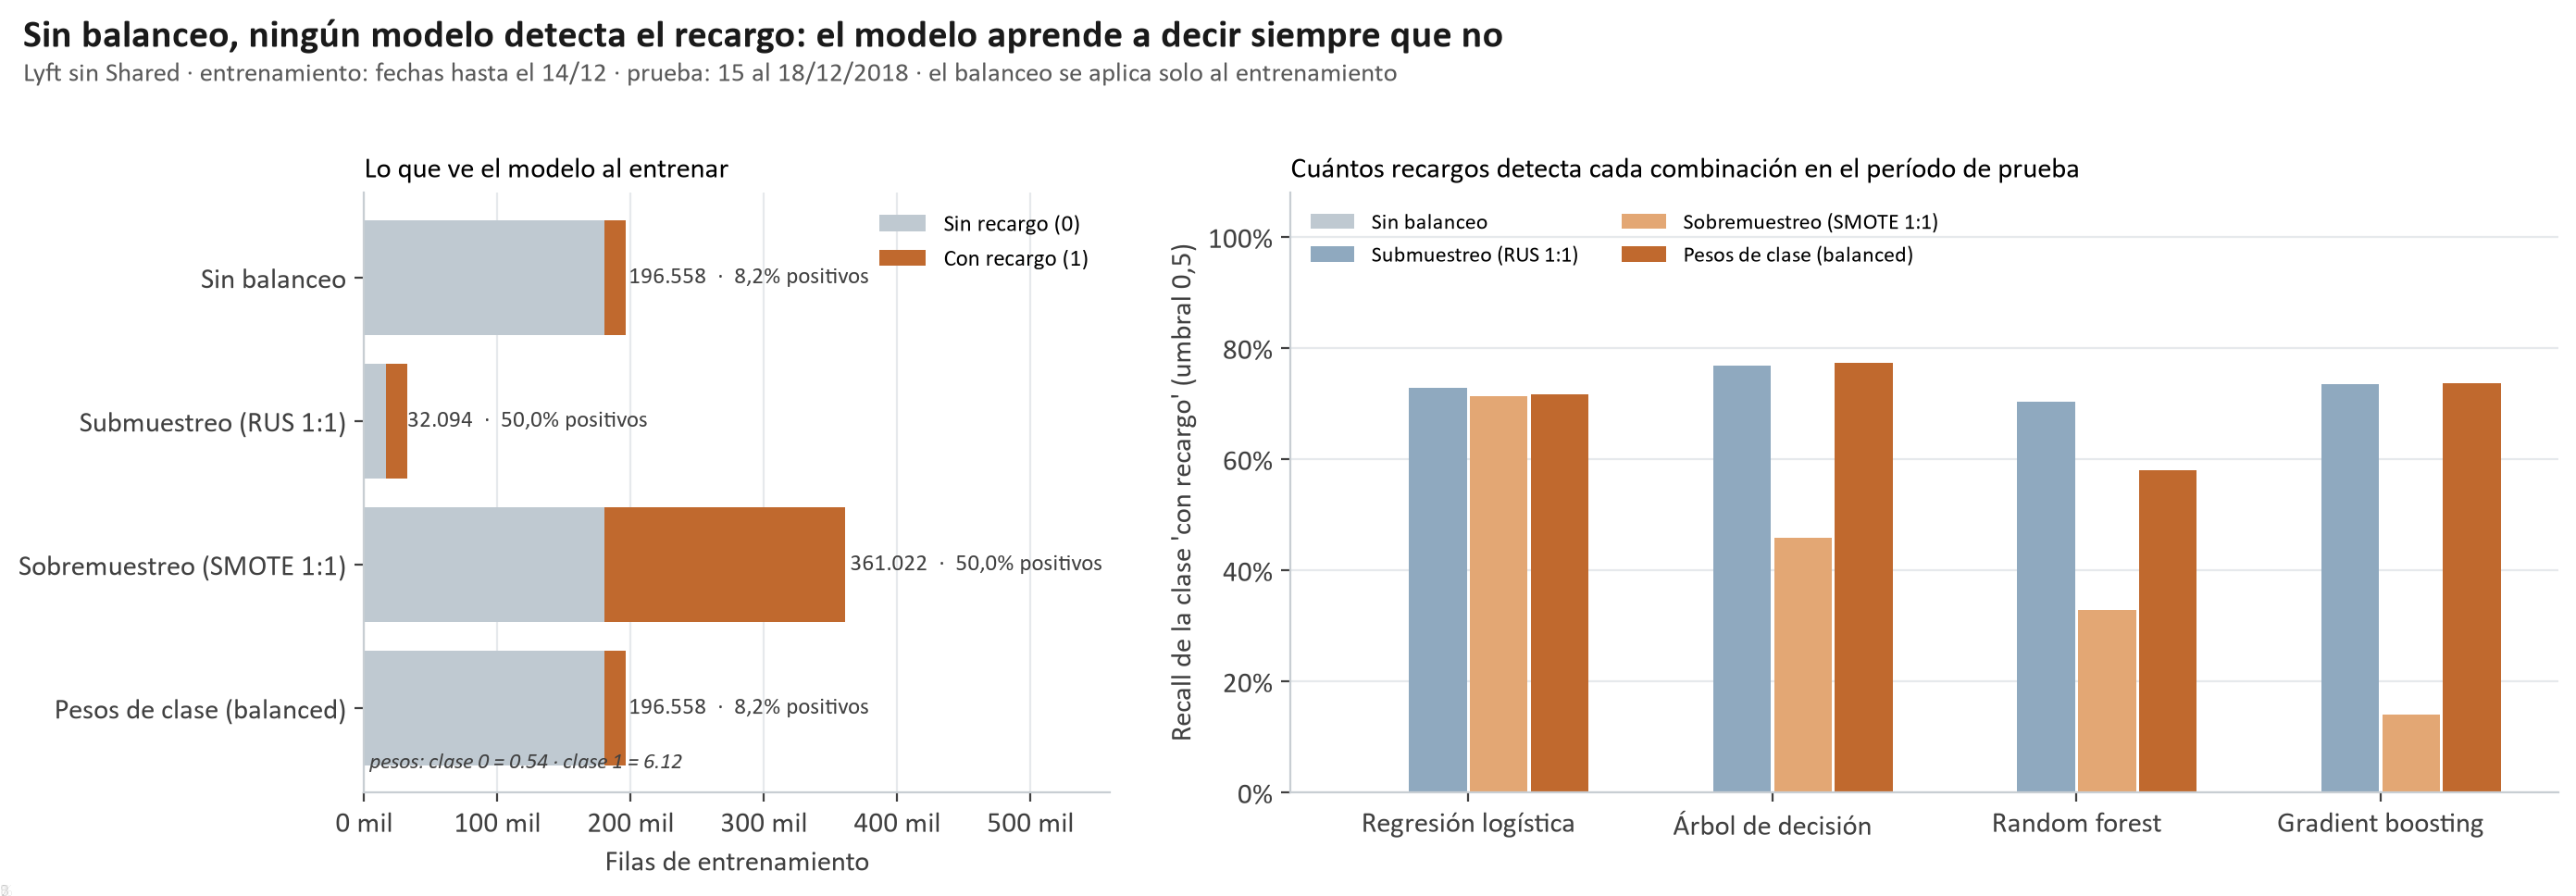

In [9]:
# @title Figura 4 · Cuántos recargos detecta cada combinación { display-mode: "form" }
figura("fig04_recargo_balanceo.png")

- **Sin balanceo** los modelos casi no detectan recargos.
- **Submuestreo** funciona, pero tira el 91% de los datos.
- **SMOTE** inventa cotizaciones imposibles (por ejemplo "0,4 de Back Bay") y no ayuda.
- **Elegimos pesos de clase por validación:** fue la de mejor resultado sin mirar la prueba, y además usa todos los datos reales.

## 8 · Modelo final: gradient boosting

Con pesos de clase y un **umbral de decisión** elegido en validación (no en la prueba).

In [10]:
# @title Métricas en los 4 días de prueba { display-mode: "form" }
filas = []
for m, r in M["A_finales"].items():
    r = r["umbral_opt"]
    filas.append([m + ("  ★" if m == M["A_elegido"] else ""), pct(r["accuracy"]), pct(r["accuracy_balanceada"]), pct(r["recall"]), pct(r["precision"]), num(r["pr_auc"])])
filas.sort(key=lambda f: "★" not in f[0])
tabla(pd.DataFrame(filas, columns=["Modelo", "Accuracy", "Accuracy balanceada", "Recall", "Precisión", "PR-AUC"]))

Modelo,Accuracy,Accuracy balanceada,Recall,Precisión,PR-AUC
Gradient boosting ★,"63,3%","62,1%","60,7%","13,1%","0,140"
Regresión logística,"56,6%","61,4%","67,1%","12,1%","0,121"
Árbol de decisión,"49,7%","63,2%","79,3%","11,9%","0,138"
Random forest,"56,1%","62,4%","69,9%","12,3%","0,141"


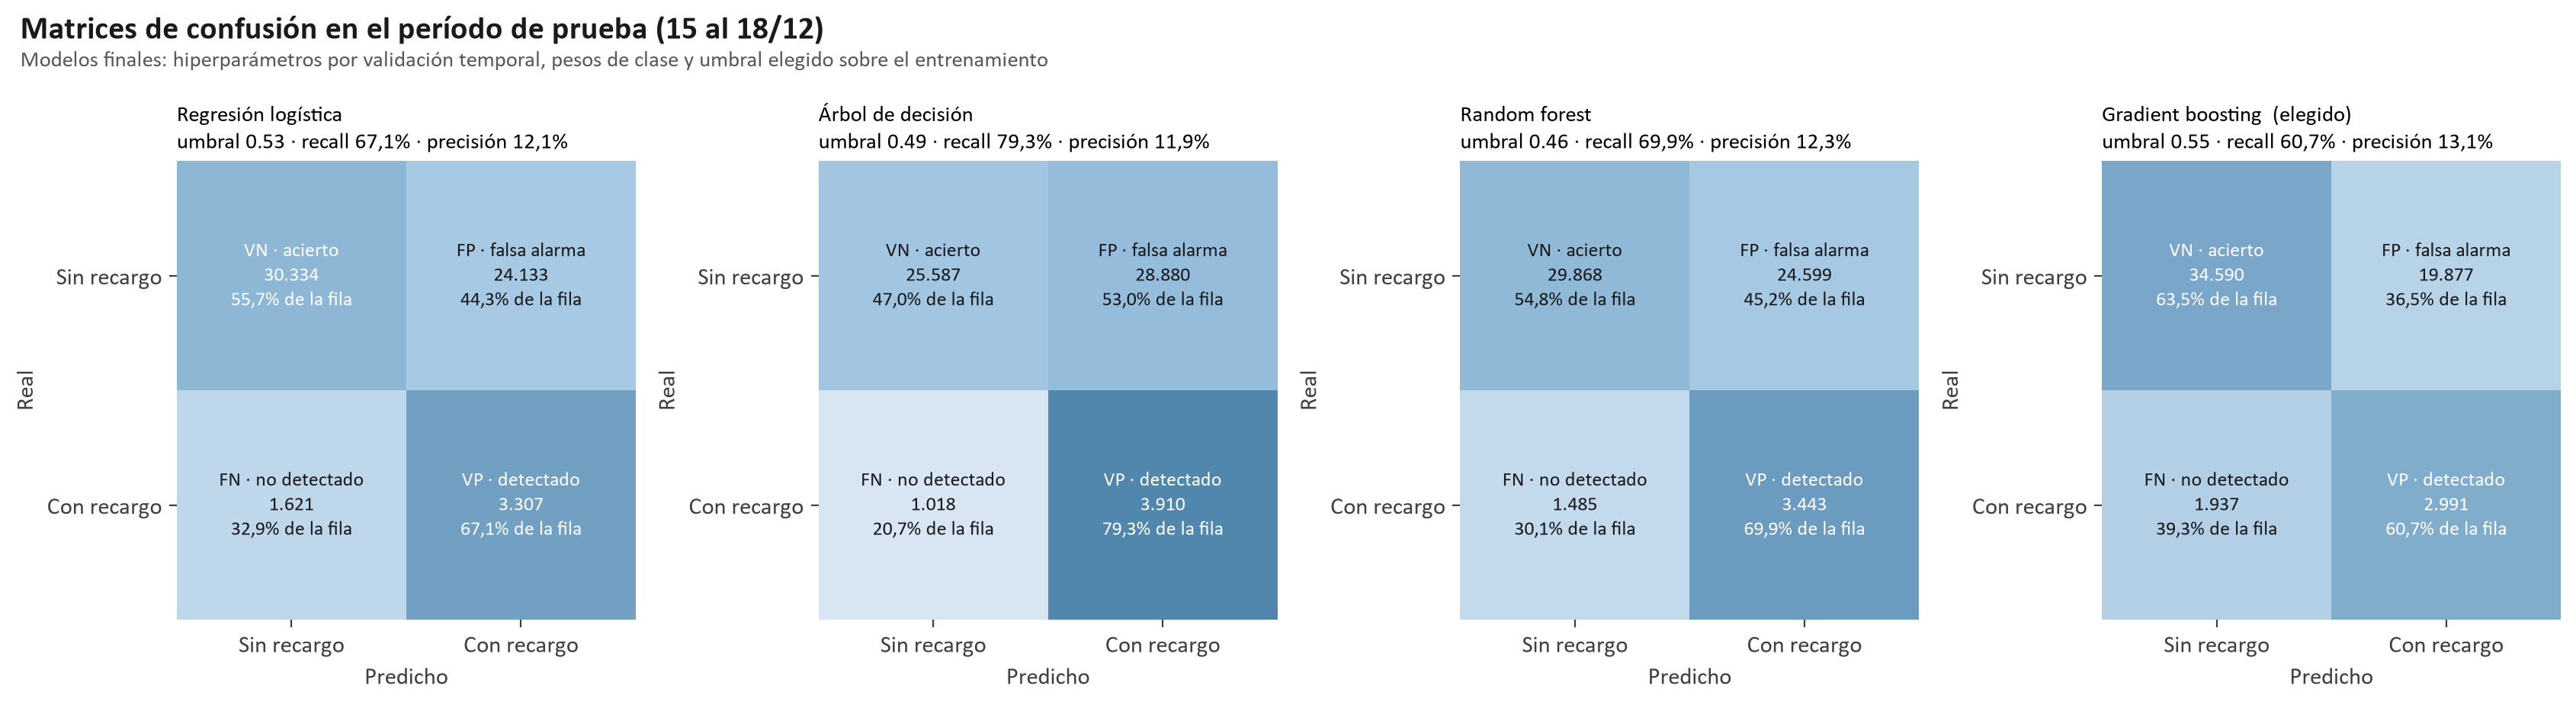

In [11]:
# @title Figura 5 · Matrices de confusión { display-mode: "form" }
figura("fig05_recargo_matrices_confusion.png")

### Cómo leer la matriz de confusión (gradient boosting)

| | Predijo **sin recargo** | Predijo **con recargo** |
|---|---|---|
| **Real: sin recargo** | **VN = 34.590** · acierto | **FP = 19.877** · falsa alarma |
| **Real: con recargo** | **FN = 1.937** · recargo no detectado | **VP = 2.991** · recargo detectado |

- **Falso positivo (FP):** el modelo avisa un recargo que no ocurre → el pasajero compara sin necesidad.
- **Falso negativo (FN):** hay recargo y el modelo no avisa → el pasajero **paga ~46% más** sin saberlo. **Es el error más caro**, por eso priorizamos detectar recargos.
- De la matriz salen las métricas: **accuracy** = (VP + VN) / total = 63,3% · **precisión** = VP / (VP + FP) = 13,1% · **recall** = VP / (VP + FN) = 60,7%.

**Cómo leer el resultado del modelo elegido:**

- **Accuracy 63,3%**, menor que el 91,7% de "decir siempre que no", porque ahora el modelo **sí avisa** recargos y a veces se equivoca.
- Acierta el **63,5%** de los viajes sin recargo y el **60,7%** de los con recargo → **accuracy balanceada 62,1%** (azar = 50%).
- De cada 100 alertas, **13** son recargos reales (el azar acierta 8).

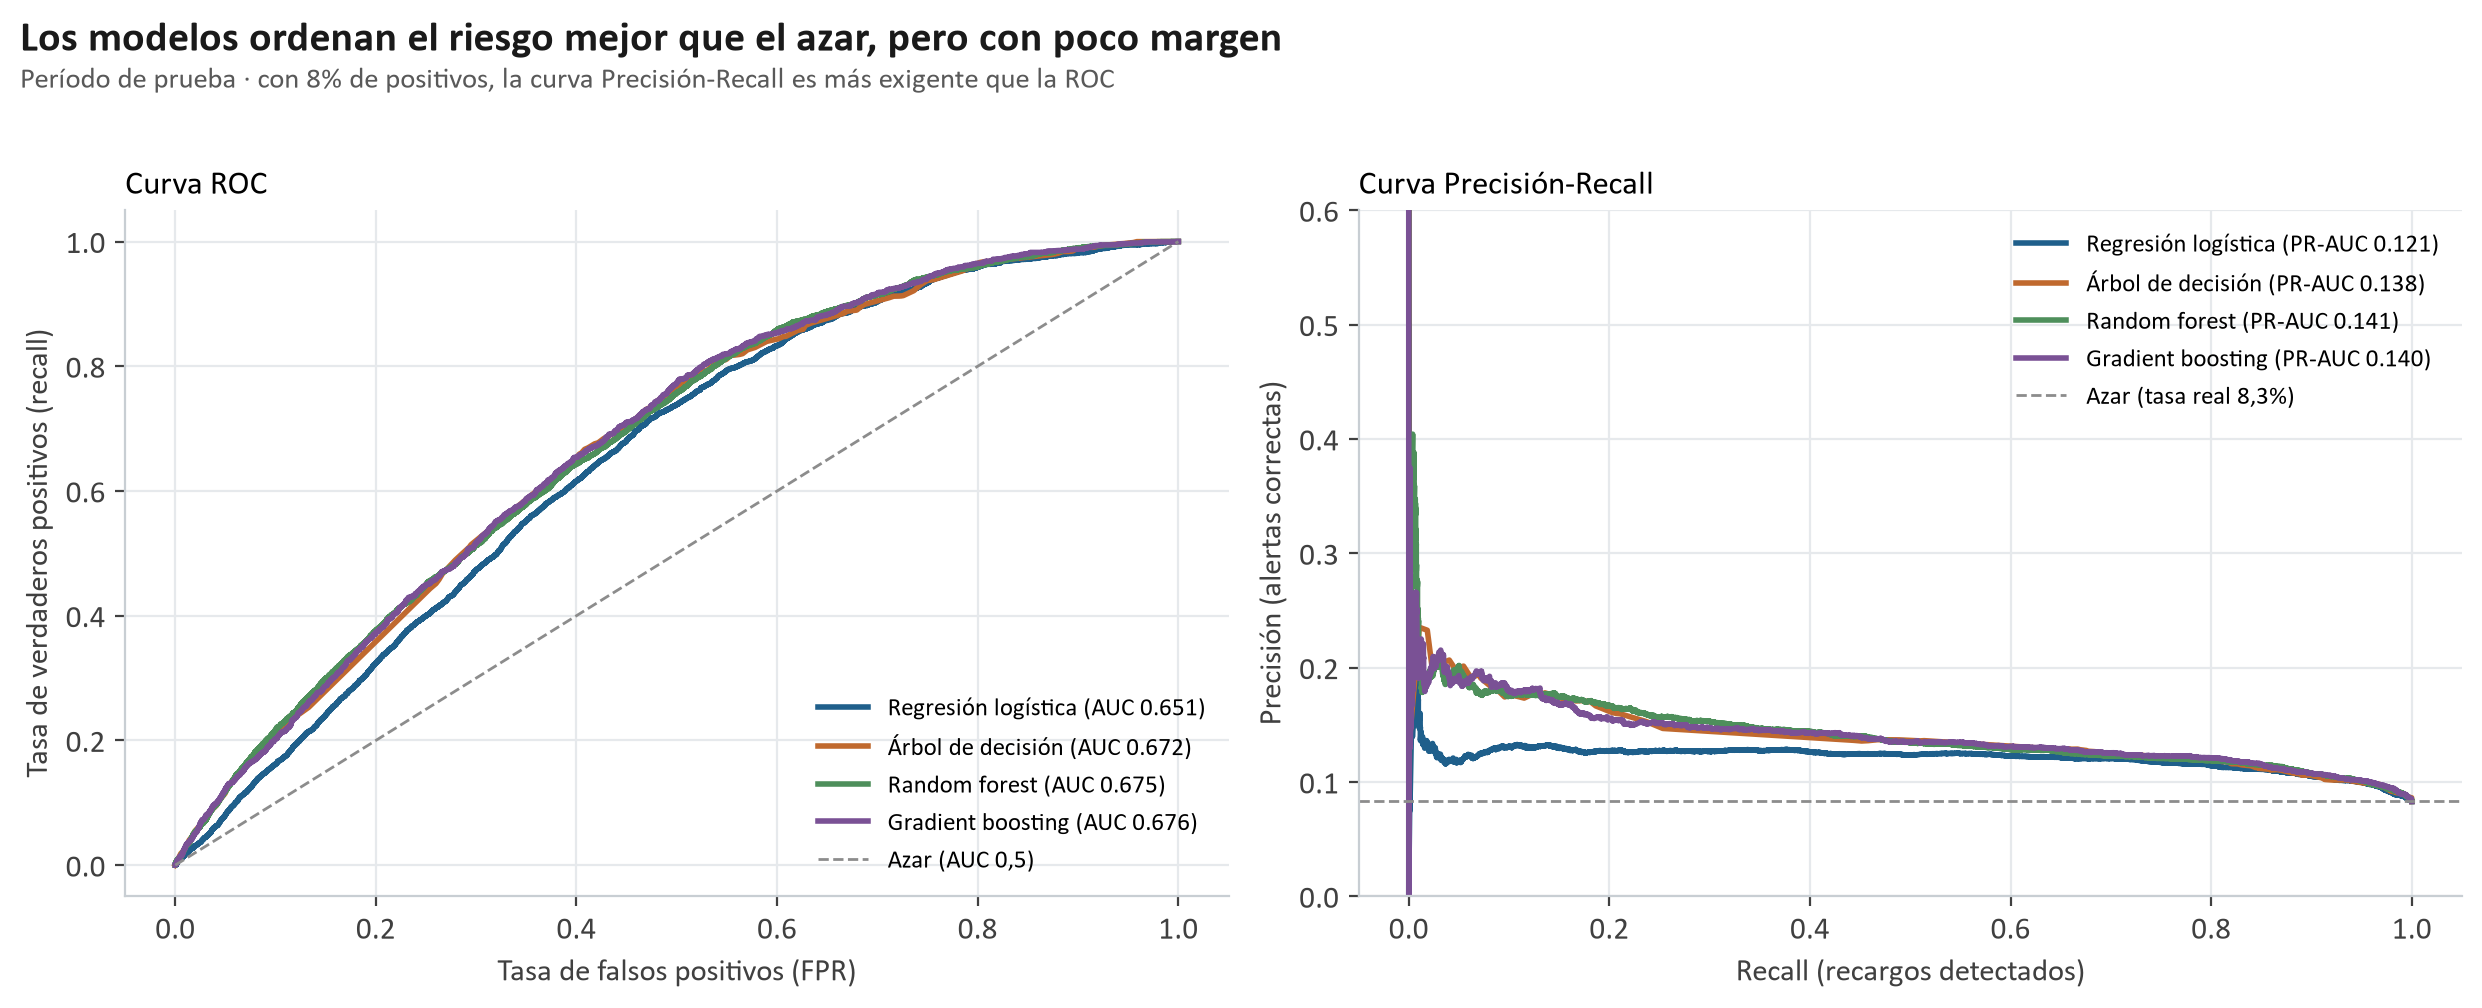

In [12]:
# @title Figura 6 · Curvas ROC y Precisión-Recall { display-mode: "form" }
figura("fig06_recargo_curvas_roc_pr.png")

Todos los modelos están por encima del azar, pero con poco margen: **el recargo es difícil de anticipar** con estos datos.

## 9 · ¿Qué aprendieron los modelos?

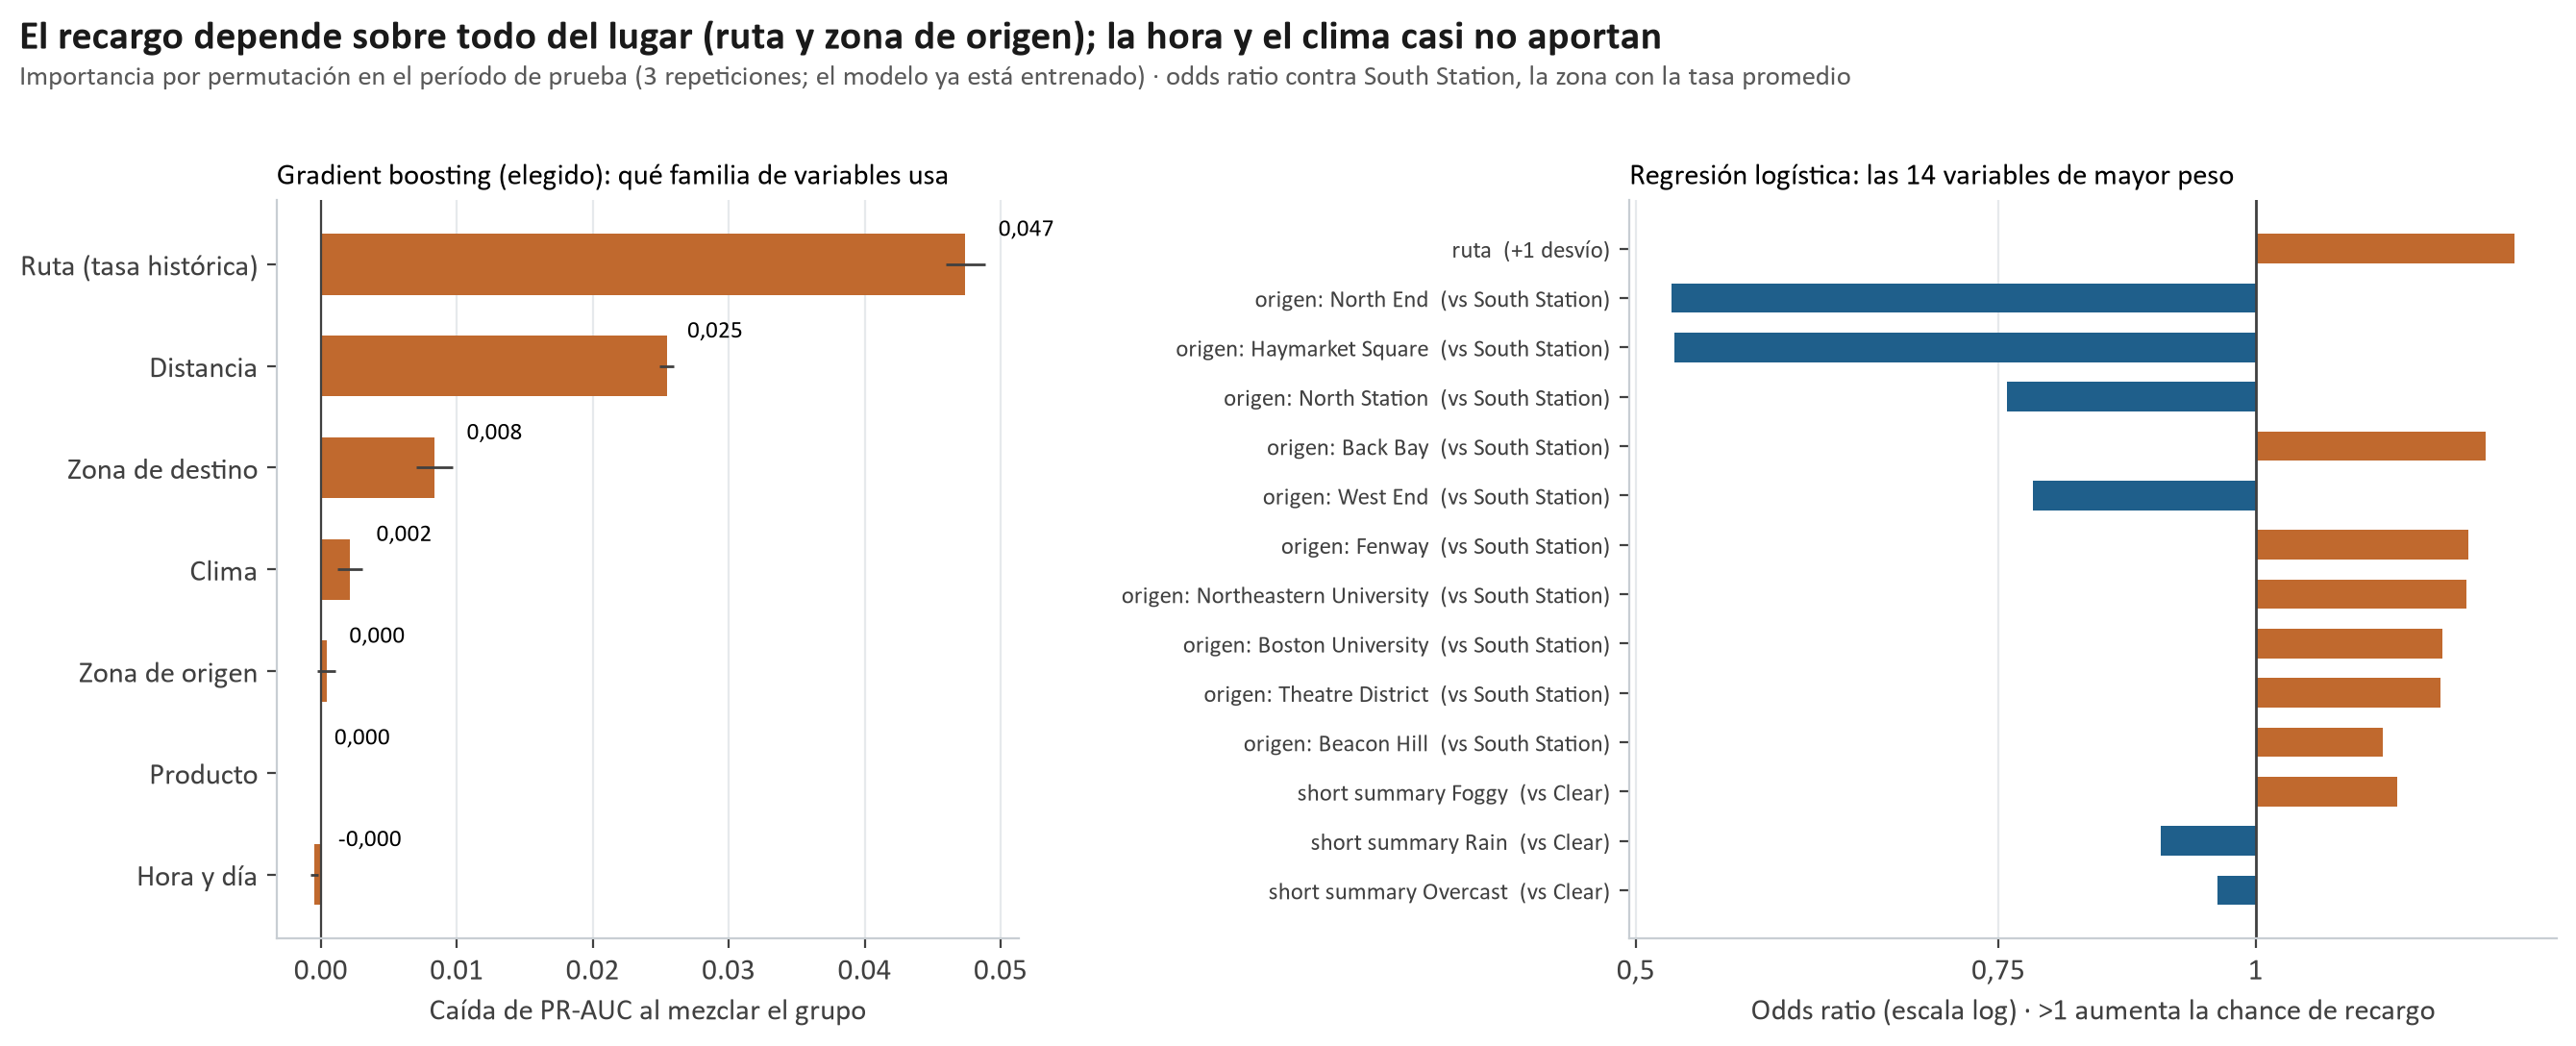

In [13]:
# @title Figura 7 · Qué variables pesan más { display-mode: "form" }
figura("fig07_recargo_importancia_odds_ratio.png")

- **El lugar es lo que más importa:** la ruta y la zona de origen.
- Comparado con South Station (zona promedio), salir de **Back Bay** multiplica la chance de recargo por 1,3; salir de **North End**, por 0,5.
- **La hora y el clima casi no aportan.**

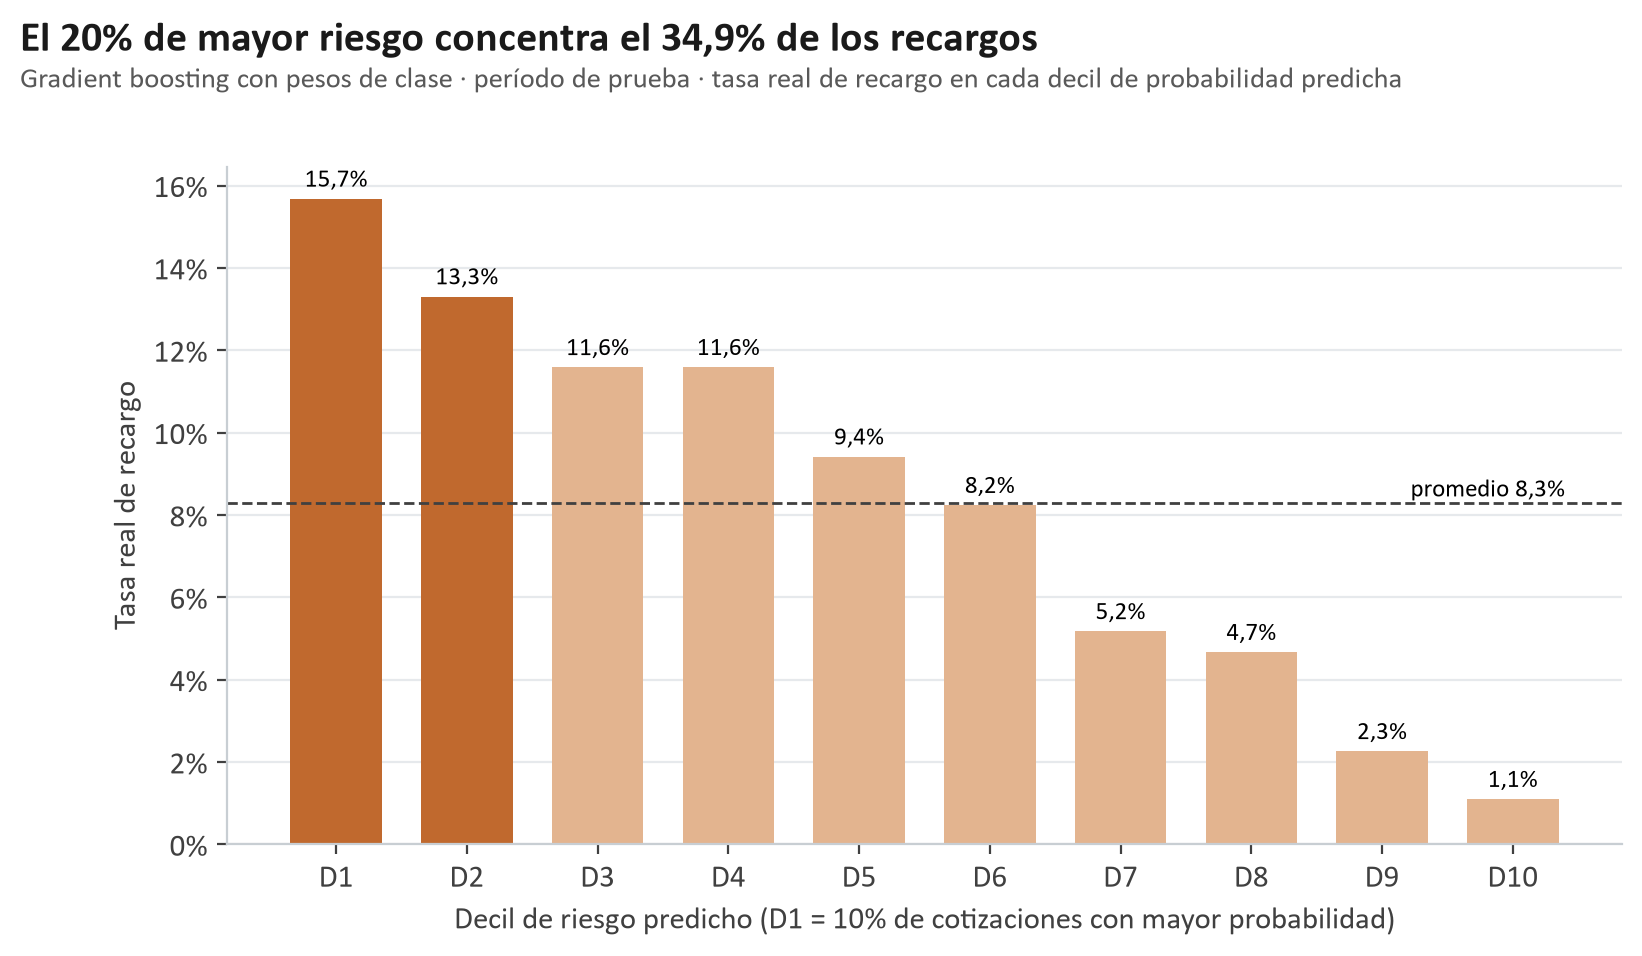

In [14]:
# @title Figura 9 · Uso práctico: ordenar el riesgo { display-mode: "form" }
figura("fig09_recargo_deciles_riesgo.png", 850)

El modelo no adivina viaje por viaje, pero **ordena el riesgo**: el 20% de cotizaciones de mayor riesgo concentra el **35%** de los recargos.

### ¿Por qué validar por fecha?

Si hubiéramos separado los datos al azar, los modelos parecerían **hasta un 87% mejores**. Es una mejora falsa: reconocen cotizaciones del mismo minuto que vieron al entrenar.

## 10 · Perfiles de rutas (K-Means)

Agrupamos las 72 rutas por **distancia** y **tasa de recargo**. La silueta es pareja para todos los k (no hay grupos naturales muy marcados), así que elegimos **k = 4** porque es fácil de interpretar.

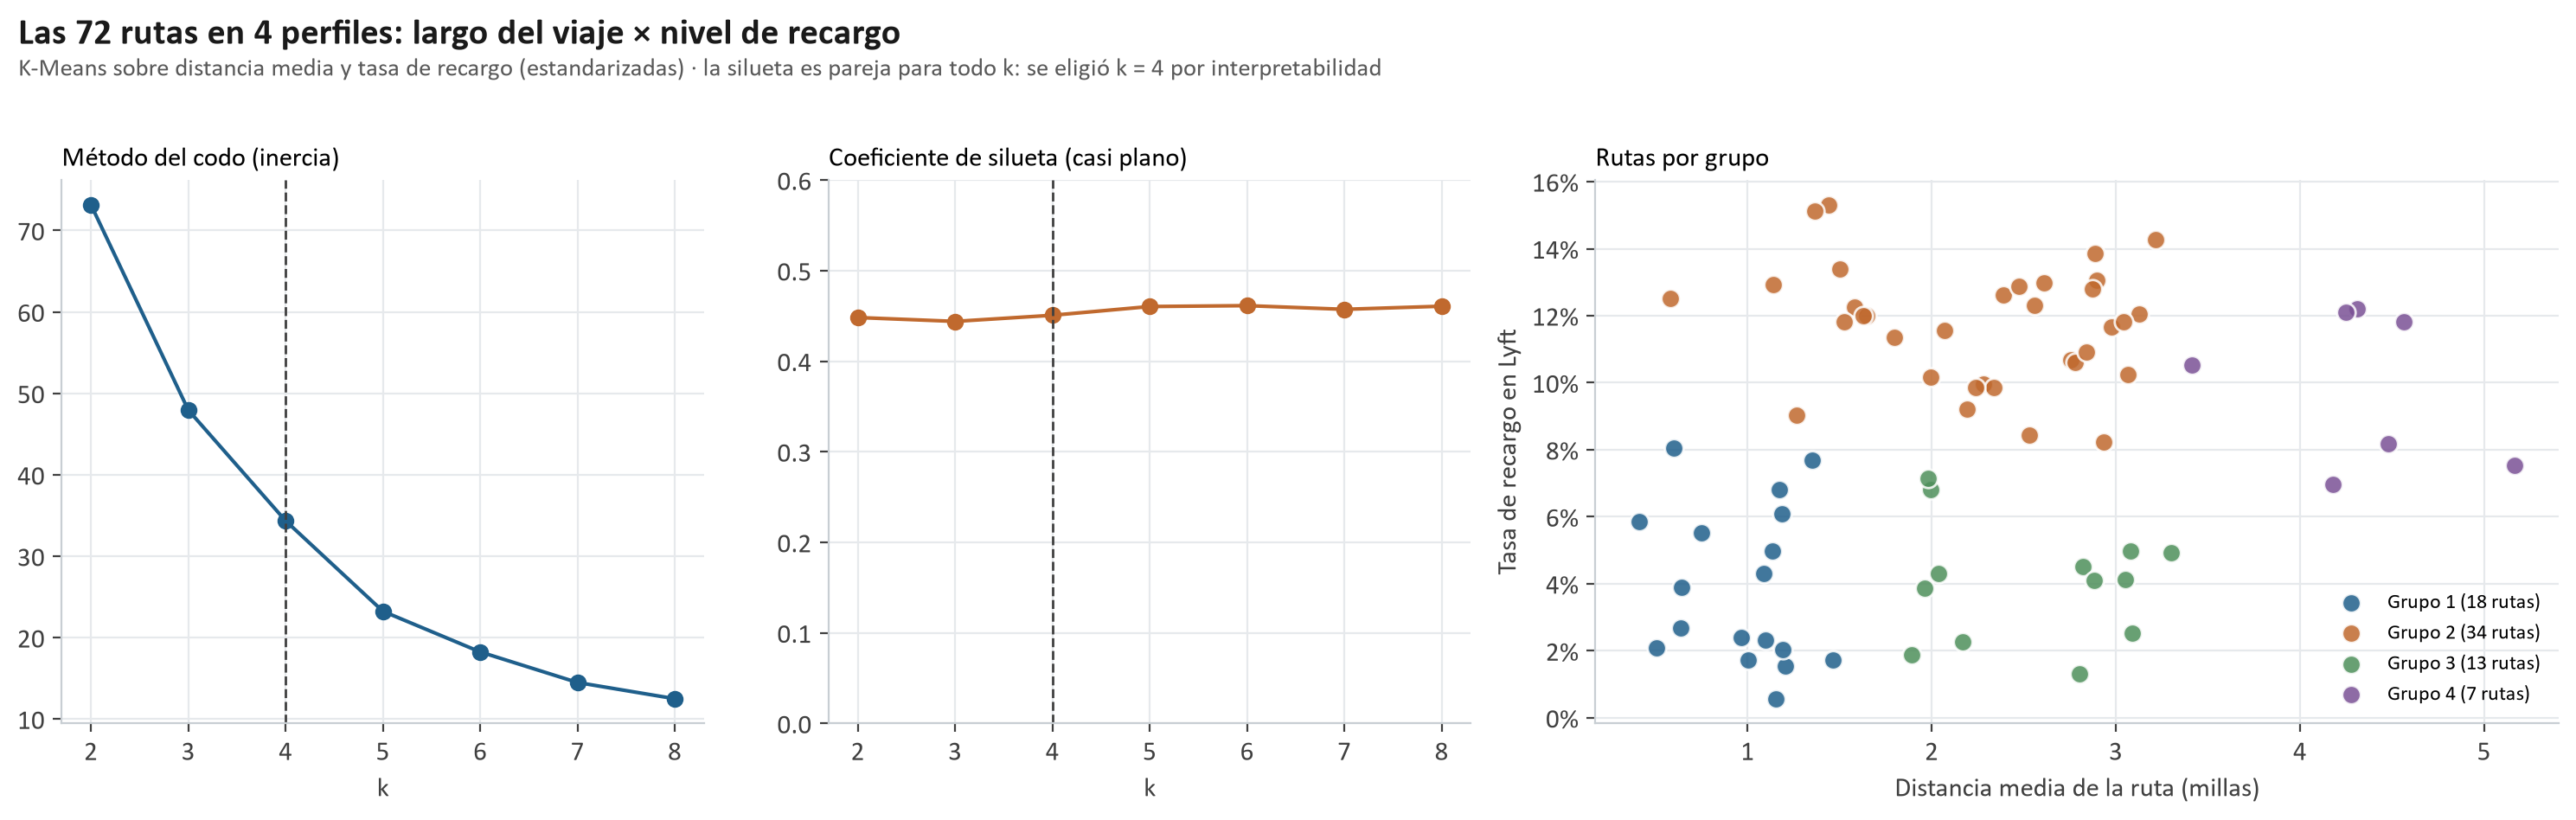

In [15]:
# @title Figura 10 · Grupos de rutas { display-mode: "form" }
figura("fig10_rutas_kmeans.png")

In [16]:
# @title Perfil de cada grupo { display-mode: "form" }
p = pd.read_csv(RES / "rutas_perfil_clusters.csv")
ej = M["C"]["ejemplos"]
tabla(pd.DataFrame({"Grupo": p["cluster"] + 1, "Rutas": p["rutas"], "Distancia media": p["distancia"].map(lambda v: num(v, 1) + " mi"),
                    "Precio por milla": p["precio_milla"].map(usd), "Recargo": p["tasa_recargo"].map(pct),
                    "Ejemplo": [ej[str(c)][0] for c in p["cluster"]]}))

Grupo,Rutas,Distancia media,Precio por milla,Recargo,Ejemplo
1,18,"1,0 mi","USD 8,81","3,9%",South Station → Financial District
2,34,"2,3 mi","USD 4,62","11,7%",Back Bay → Boston University
3,13,"2,5 mi","USD 4,09","4,1%",South Station → West End
4,7,"4,3 mi","USD 3,02","9,9%",Fenway → Financial District


- Las rutas **cortas** son las más caras por milla por la tarifa base (H4). Ejemplo: Financial District → South Station, USD 17,95 por milla.
- El recargo alto aparece en rutas de **distintas distancias**, siempre saliendo del oeste (Back Bay, Fenway, universidades). Coincide con el modelo de clasificación.

## 11 · Conclusiones

| Hipótesis | Resultado |
|---|---|
| H1 · Producto y distancia definen el precio | ✔ Confirmada |
| H2 · Uber y Lyft difieren según el nivel | ✔ Confirmada |
| H3 · Hay patrones horarios | ✘ No se confirma |
| H4 · Hay rutas más caras por milla | ✔ Confirmada (las cortas) |
| H5 · El mal clima encarece | ✘ Rechazada |
| H6 · Hay segmentos de viajes | ≈ Parcial |

### Respuesta al problema

1. **El precio es predecible:** con el producto, la distancia y el multiplicador se estima con un error de ~USD 1,08.
2. **El recargo es lo difícil de anticipar:** depende del **lugar**, no de la hora ni del clima. Lo demás depende de la oferta y la demanda en tiempo real, que no están en los datos.
3. **Valor práctico:** si salís de Back Bay, Fenway o las universidades, conviene **comparar con Uber** o caminar a una zona vecina.

**Próximo paso (Entrega 4):** contar esta historia para el pasajero, el conductor y la plataforma.

---
### Anexo · Dónde está cada cosa

| Carpeta | Contenido |
|---|---|
| `1_Informe/` | Informe completo, con todos los detalles técnicos |
| `3_Codigo/` | `modelado_entrega3.py`: reproduce todo |
| `4_Datasets/` | Datasets de modelado y balanceados |
| `5_Graficos/` y `6_Resultados/` | Figuras y tablas |